# Notebook 10: Target Variable Analysis

## Topic 1: Identify the Target Variable

### Step 1: Understand the Concept

A target variable is the value that a machine learning model is expected to predict. It is also called the dependent variable or prediction target.

There are two common target types:

- **Classification Target:** Predicts a category or class, such as Fraud or Not Fraud.
- **Regression Target:** Predicts a numerical value, such as price, quantity, or revenue.

In the Online Retail II dataset, `Price` and `Quantity` are numerical columns that could be considered for regression tasks. However, the correct target depends on the business objective.

The dataset does not provide a predefined classification target. A classification target must be selected or created based on a clearly defined business problem.

## Step 2: Demonstrate the Concept

### Simple Example

Suppose we have the following data:

| Hours Studied | Exam Mark |
|---:|---:|
| 2 | 40 |
| 4 | 60 |
| 6 | 80 |

If we want to predict exam marks, `Exam Mark` is the target variable, and `Hours Studied` is the input feature.

### Real-World Example

An online retailer may use historical information to predict the quantity of products customers will purchase.

### Business Example

A business may want to predict item prices to support pricing analysis and planning.

### AI/ML Use Case

The target variable determines the type of machine learning problem, the model selection, and the evaluation metrics.

### Important Characteristics

- A target represents the value to be predicted.
- Features provide information used to make predictions.
- Classification targets contain categories.
- Regression targets contain numerical values.
- The target must match the actual business objective.

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "online_retail_II.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:

# Identify possible target variables

print("Dataset shape:", df.shape)

target_candidates = ["Price", "Quantity"]

for column in target_candidates:
    if column in df.columns:
        print(f"\nColumn: {column}")
        print("Data type:", df[column].dtype)
        print("Missing values:", df[column].isna().sum())
        print("Unique values:", df[column].nunique())
        print("Sample values:")
        display(df[column].dropna().head())
    else:
        print(f"{column} is not available in the dataset.")

print("\nAll dataset columns:")
print(df.columns.tolist())



Dataset shape: (525461, 8)

Column: Price
Data type: float64
Missing values: 0
Unique values: 1606
Sample values:


0    6.95
1    6.75
2    6.75
3    2.10
4    1.25
Name: Price, dtype: float64


Column: Quantity
Data type: int64
Missing values: 0
Unique values: 825
Sample values:


0    12
1    12
2    12
3    48
4    24
Name: Quantity, dtype: int64


All dataset columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

The code examines `Price` and `Quantity` to understand whether they could be suitable numerical target variables for a regression task.

It displays each column's data type, missing value count, number of unique values, and sample values.

### 2. Why These Methods Are Used

- `df.shape` checks the dataset dimensions.
- `.dtype` identifies the data type.
- `.isna().sum()` counts missing values.
- `.nunique()` counts distinct non-missing values.
- `.head()` displays sample observations.

### 3. How to Interpret the Output

- **Data Type:** Helps determine whether a column is numeric or categorical.
- **Missing Values:** Shows how many records need further investigation.
- **Unique Values:** Indicates how many distinct values appear in the column.
- **Sample Values:** Helps understand what the data represents.

### 4. AI/ML Pipeline Impact

Selecting the correct target defines the prediction task. Missing target values, invalid data, and an unclear prediction objective can affect model training and evaluation.

### Conclusion

Target variable identification is an essential first step before machine learning. In this dataset, `Price` and `Quantity` are possible regression targets, but the final selection depends on the business objective.

## Step 1: Understand the Concept – Class Distribution

Class Distribution is the process of understanding how records are distributed among different classes in a classification dataset.

It helps us identify which class has more records and which class has fewer records.

For example, a dataset may contain two classes:
- Positive Quantity
- Zero or Negative Quantity

The distribution of these classes helps us understand whether the dataset is balanced or imbalanced.

**Importance in AI/ML:**
Class distribution analysis helps identify class imbalance before training a classification model. A model trained on an imbalanced dataset may perform better on the majority class than on the minority class.

**Note:** The Online Retail II dataset does not contain a predefined classification target. In this notebook, we use `Quantity` to create example classes for learning purposes only.

## Step 2: Demonstrate the Concept – Simple Example

Imagine an online retail dataset containing 1,000 transactions.

| Class | Number of Records |
|---|---:|
| Positive Quantity | 900 |
| Zero or Negative Quantity | 100 |
| Total | 1,000 |

In this example, Positive Quantity represents 90% of the records, while Zero or Negative Quantity represents 10%.

This shows that the two classes are not equally distributed.

In a real-world retail dataset, this analysis helps us understand the distribution of different transaction types before using them in a machine learning workflow.

**Note:** These numbers are hypothetical examples, not actual dataset results.

In [7]:
# Create classes using the Quantity column
df["Quantity_Class"] = np.where(
    df["Quantity"] > 0,
    "Positive Quantity",
    "Zero or Negative Quantity"
)

# Calculate class distribution in percentages
class_distribution = (
    df["Quantity_Class"]
    .value_counts(normalize=True)
    .mul(100)
)

# Display the result
print("Class Distribution (%):")
display(class_distribution.rename("Percentage").to_frame())

Class Distribution (%):


,Percentage
Quantity_Class,
Positive Quantity,97.65425
Zero or Negative Quantity,2.34575


## Step 3: Code Explanation and Analysis

**1. `np.where()`**

Creates a new column named `Quantity_Class`.

- If `Quantity` is greater than 0, the record is classified as `Positive Quantity`.
- If `Quantity` is 0 or less, the record is classified as `Zero or Negative Quantity`.

**2. `value_counts(normalize=True, dropna=False)`**

Calculates the proportion of records belonging to each class.

**3. `.mul(100)`**

Converts the proportions into percentages.

**4. `rename("Percentage").to_frame()`**

Displays the results in a readable table with the column name `Percentage`.

### How to Interpret the Output

- A higher percentage indicates that a class contains more records.
- A lower percentage indicates that a class contains fewer records.
- A large difference between class percentages may indicate class imbalance.

### Where It Is Used in AI/ML

Class distribution analysis is used before training classification models to understand the representation of each class.

**Important:** These classes are created only for demonstration. Positive Quantity and Zero or Negative Quantity are not predefined business target labels. Actual class percentages depend on the dataset.

## Step 1: Understand the Concept – Class Counts

Class Counts is the process of counting how many records belong to each class in a classification dataset.

It helps us understand the number of records available in every class.

For example:
- Positive Quantity: 900 records
- Zero or Negative Quantity: 100 records

Class counts show the actual number of records in each class, rather than their percentages.

**Importance in AI/ML:**
Class counts help identify whether one class has significantly more records than another before training a classification model.

## Step 2: Demonstrate the Concept – Simple Example

Imagine an online retail dataset with 1,000 records.

| Class | Number of Records |
|---|---:|
| Positive Quantity | 900 |
| Zero or Negative Quantity | 100 |
| Total | 1,000 |

In this example, Positive Quantity has more records than Zero or Negative Quantity.

This comparison helps us understand how many records belong to each class.

**Note:** These counts are hypothetical examples, not actual dataset results.

In [8]:
# Count the records in each class
class_counts = df["Quantity_Class"].value_counts()

# Display the class counts
print("Class Counts:")
display(class_counts.rename("Count").to_frame())

# Display the total number of records
print("Total records:", class_counts.sum())

Class Counts:


,Count
Quantity_Class,
Positive Quantity,513135
Zero or Negative Quantity,12326


Total records: 525461


## Step 3: Code Explanation and Analysis

**1. `value_counts()`**

Counts the number of records belonging to each class in the `Quantity_Class` column.

**2. `rename("Count")`**

Names the output column `Count` to make the results easier to understand.

**3. `to_frame()`**

Converts the resulting Series into a DataFrame table.

**4. `class_counts.sum()`**

Calculates the total number of records across all classes.

### How to Interpret the Output

- A higher count means more records belong to that class.
- A lower count means fewer records belong to that class.
- A large difference between class counts may indicate class imbalance.

### Where It Is Used in AI/ML

Class counts are useful when checking how many training examples are available for each class before building a classification model.

**Note:** This analysis uses demonstration classes created from `Quantity`, not a predefined target variable in the Online Retail II dataset.

## Step 1: Understand the Concept – Class Percentages

Class Percentages show what percentage of the total records belongs to each class.

Class counts tell us the actual number of records, while class percentages tell us how much each class contributes to the entire dataset.

**Formula:**

Class Percentage = (Number of Records in a Class / Total Number of Records) × 100

**Importance in AI/ML:**

Class percentages help us compare classes even when datasets have different total numbers of records. They also help us identify possible class imbalance before training a classification model.

## Step 2: Demonstrate the Concept – Simple Example

Imagine an online retail dataset containing 1,000 records.

| Class | Count | Percentage |
|---|---:|---:|
| Positive Quantity | 900 | 90% |
| Zero or Negative Quantity | 100 | 10% |
| Total | 1,000 | 100% |

In this example, 90% of the records belong to Positive Quantity, and 10% belong to Zero or Negative Quantity.

The percentages make it easier to compare the sizes of the two classes.

**Note:** These values are hypothetical examples, not actual dataset results.

In [9]:
# Calculate the percentage of records in each class
class_percentages = (
    df["Quantity_Class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Display class percentages
print("Class Percentages:")
display(class_percentages.rename("Percentage (%)").to_frame())

# Check the total percentage
print("Total Percentage:", round(class_percentages.sum(), 2), "%")

Class Percentages:


,Percentage (%)
Quantity_Class,
Positive Quantity,97.65
Zero or Negative Quantity,2.35


Total Percentage: 100.0 %


## Step 3: Code Explanation and Analysis

**1. `value_counts(normalize=True)`**

Calculates the proportion of records belonging to each class instead of returning only the counts.

**2. `.mul(100)`**

Converts the proportions into percentages.

**3. `.round(2)`**

Rounds the percentages to two decimal places for readability.

**4. `.rename("Percentage (%)").to_frame()`**

Displays the results as a table with a clear column name.

**5. `class_percentages.sum()`**

Adds the displayed percentages to check whether they total approximately 100%. Small differences can occur because of rounding.

### How to Interpret the Output

- A high percentage means that a class represents a large share of the dataset.
- A low percentage means that a class represents a small share.
- A large gap between class percentages may indicate class imbalance.

### Where It Is Used in AI/ML

Class percentages help us understand whether the training data represents each class adequately. If one class is underrepresented, we may need to evaluate suitable methods for handling class imbalance.

**Note:** These are demonstration classes created from the `Quantity` column; they are not predefined business target labels.

## Step 1: Understand the Concept – Class Imbalance

Class Imbalance occurs when one class has significantly more records than another class in a classification dataset.

For example, if 95% of records belong to one class and only 5% belong to another class, the dataset has a strong class imbalance.

Class imbalance can affect machine learning model performance because the model may learn to predict the majority class more often than the minority class.

**Importance in AI/ML:**
Identifying class imbalance helps us choose suitable evaluation metrics and decide whether techniques such as class weighting or resampling are needed.

## Step 2: Demonstrate the Concept – Simple Example

Imagine an online retail classification dataset containing 1,000 records.

| Class | Count | Percentage |
|---|---:|---:|
| Positive Quantity | 950 | 95% |
| Zero or Negative Quantity | 50 | 5% |
| Total | 1,000 | 100% |

In this example, Positive Quantity is the majority class, while Zero or Negative Quantity is the minority class.

The difference between these classes indicates a strong imbalance.

**Real-world example:** In fraud detection, legitimate transactions may be much more common than fraudulent transactions. A model that predicts every transaction as legitimate could achieve high accuracy while failing to identify fraud.

**Note:** The table contains hypothetical values, not actual dataset results.

In [10]:
# Calculate class counts
class_counts = df["Quantity_Class"].value_counts()

# Calculate class percentages
class_percentages = (
    df["Quantity_Class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Combine counts and percentages
class_analysis = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages
})

# Display class analysis
print("Class Imbalance Analysis:")
display(class_analysis)

# Identify majority and minority classes
print("Majority Class:", class_counts.idxmax())
print("Minority Class:", class_counts.idxmin())

# Calculate the imbalance ratio
minority_count = class_counts.min()
majority_count = class_counts.max()

imbalance_ratio = majority_count / minority_count

print("Imbalance Ratio:", round(imbalance_ratio, 2))

Class Imbalance Analysis:


,Count,Percentage (%)
Quantity_Class,,
Positive Quantity,513135,97.65
Zero or Negative Quantity,12326,2.35


Majority Class: Positive Quantity
Minority Class: Zero or Negative Quantity
Imbalance Ratio: 41.63


## Step 3: Code Explanation and Analysis

**1. `value_counts()`**

Counts the records belonging to each class.

**2. `value_counts(normalize=True)`**

Calculates the proportion of records in each class. Multiplying by 100 converts these proportions into percentages.

**3. `pd.DataFrame()`**

Combines the class counts and percentages into one table for easier comparison.

**4. `idxmax()`**

Returns the class name with the highest count, identifying the majority class.

**5. `idxmin()`**

Returns the class name with the lowest count, identifying the minority class.

**6. Imbalance Ratio**

The imbalance ratio is calculated by dividing the majority class count by the minority class count.

For example, a ratio of 19 means the majority class has 19 times as many records as the minority class.

### How to Interpret the Output

- A ratio close to 1 indicates that the class counts are similar.
- A larger ratio indicates a greater difference between class counts.
- There is no single ratio that defines imbalance for every machine learning problem.

### Where It Is Used in AI/ML

Class imbalance analysis helps determine whether to consider class weights, oversampling, undersampling, or evaluation metrics such as precision, recall, and F1-score.

**Important:** Our `Quantity_Class` is a demonstration label created from the `Quantity` column. It is not a predefined classification target, and the analysis alone does not establish whether a real business problem is imbalanced.

## Step 1: Understand the Concept – Target Distribution

Target Distribution is the process of understanding how the values of a numerical target variable are spread across a dataset.

In regression problems, the target variable contains numerical values that a machine learning model learns to predict.

For the Online Retail II dataset, `Price` or `Quantity` could be a regression target depending on the business objective.

Target distribution analysis helps us identify:
- How values are spread across the dataset
- Whether values are concentrated in a particular range
- Whether the distribution is symmetric or skewed
- Whether unusually high or low values are present

**Importance in AI/ML:**
Understanding the target distribution helps us choose suitable evaluation methods and identify data patterns before training a regression model.

## Step 2: Demonstrate the Concept – Simple Example

Imagine an online retail dataset where `Price` represents the price of each product.

| Product | Price |
|---|---:|
| Product A | 10 |
| Product B | 15 |
| Product C | 20 |
| Product D | 25 |
| Product E | 100 |

Most prices in this example are between 10 and 25, but one product has a price of 100.

A target distribution analysis helps us understand this spread and identify whether a few values differ substantially from the rest.

**Real-world use:** A business may analyze product prices before building a regression model to predict prices or estimate sales revenue.

**Note:** These values are hypothetical examples.

Target Distribution Analysis:


,Price
count,525461.000000
mean,4.688834
std,146.126914
min,-53594.360000
25%,1.250000
50%,2.100000
75%,4.210000
max,25111.090000


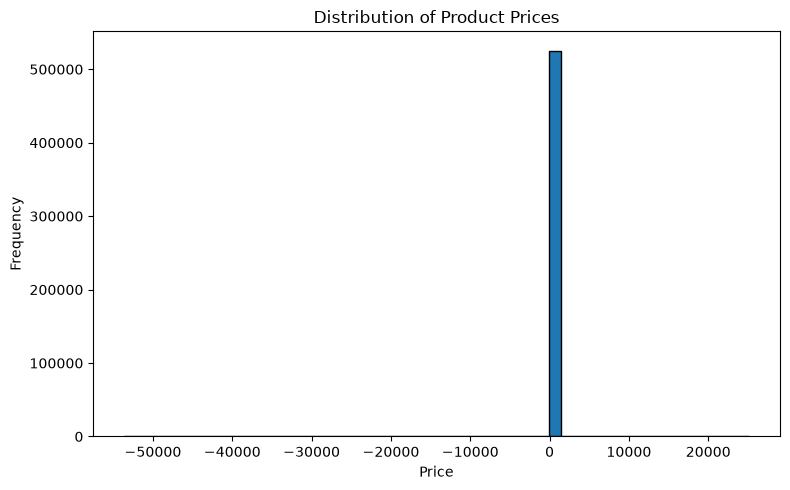

In [11]:
# Select Price as the example regression target
target = df["Price"].dropna()

# Display descriptive statistics
print("Target Distribution Analysis:")
display(target.describe().to_frame())

# Plot the target distribution
plt.figure(figsize=(8, 5))
plt.hist(target, bins=50, edgecolor="black")
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Step 3: Code Explanation and Analysis

**1. `df["Price"]`**

Selects the `Price` column as the example numerical target variable.

**2. `.dropna()`**

Removes missing values from the selected target for this analysis. It does not modify the original DataFrame.

**3. `.describe()`**

Displays summary statistics such as count, mean, standard deviation, minimum, quartiles, and maximum.

**4. `plt.hist()`**

Creates a histogram to show how frequently price values occur across different ranges.

**5. `plt.figure()` and `plt.tight_layout()`**

Set the plot size and help arrange its elements clearly.

### How to Interpret the Output

- The histogram shows where prices are concentrated.
- A long tail on one side may indicate a skewed distribution.
- Values far from the main concentration may need further investigation.
- The plot alone does not prove that any value is incorrect.

### Where It Is Used in AI/ML

Target distribution analysis helps us understand the numerical variable before building a regression model. It can also guide decisions about transformations and further investigation of extreme values.

**Important:** `Price` is used here as an example target. The correct target depends on the actual business question, and this analysis does not automatically remove any records.

## Step 1: Understand the Concept – Mean

Mean is the average value of a numerical variable. It is calculated by adding all the values and dividing the sum by the total number of values.

In regression target analysis, the mean helps us understand the average value of the target variable.

For the Online Retail II dataset, we can use the `Price` column to calculate the average product price.

**Importance in AI/ML:**
The mean helps us understand the typical numerical level of a target variable and is used in statistical analysis and some machine learning methods.

**Formula:**

Mean = Sum of all values / Number of values

## Step 2: Demonstrate the Concept – Simple Example

Imagine five products with the following prices:

| Product | Price |
|---|---:|
| Product A | 10 |
| Product B | 20 |
| Product C | 30 |
| Product D | 40 |
| Product E | 50 |
| Total | 150 |

Mean Price = 150 / 5 = 30

The average price of these five products is 30.

**Real-world use:** A retail business can calculate the mean product price to understand the average price level in its inventory.

**Note:** These are hypothetical values, not actual dataset results.

In [12]:
# Select the regression target
target = df["Price"].dropna()

# Calculate the mean
mean_price = target.mean()

# Display the result
print("Mean Price:", round(mean_price, 2))

Mean Price: 4.69


## Step 3: Code Explanation and Analysis

**1. `df["Price"]`**

Selects the `Price` column from the dataset.

**2. `.dropna()`**

Excludes missing price values from the calculation without changing the original DataFrame.

**3. `.mean()`**

Calculates the average of the available price values.

**4. `round(mean_price, 2)`**

Rounds the result to two decimal places for easier reading.

### How to Interpret the Output

The displayed value represents the average `Price` across records with non-missing prices.

The mean can be affected by extremely high or low values, so it should be interpreted alongside other statistics such as the median.

### Where It Is Used in AI/ML

The mean helps us understand the target variable before training a regression model. It can also serve as a simple baseline prediction in some regression tasks.

**Important:** This calculates the average recorded price, not total sales revenue. The correct target depends on the business problem.

## Step 1: Understand the Concept – Median

Median is the middle value of a numerical dataset when all values are arranged in ascending or descending order.

If the dataset contains an even number of values, the median is the average of the two middle values.

In regression target analysis, the median helps us understand the central value of a numerical target variable.

**Importance in AI/ML:**
The median is less affected by extreme values than the mean. Therefore, it is useful when analyzing skewed data or datasets containing outliers.

## Step 2: Demonstrate the Concept – Simple Example

Consider the following product prices arranged in ascending order:

| Product | Price |
|---|---:|
| Product A | 10 |
| Product B | 20 |
| Product C | 30 |
| Product D | 40 |
| Product E | 100 |

There are five values, so the middle value is 30.

**Median Price = 30**

Even though the last price is 100, the median remains 30 because it depends on the middle position of the sorted values.

**Real-world use:** A retail business can use the median price to understand the central product price when a few products are much more expensive than others.

**Note:** These are hypothetical values.

In [13]:
# Select the regression target
target = df["Price"].dropna()

# Calculate the median
median_price = target.median()

# Display the result
print("Median Price:", round(median_price, 2))

Median Price: 2.1


## Step 3: Code Explanation and Analysis

**1. `df["Price"]`**

Selects the `Price` column from the dataset.

**2. `.dropna()`**

Excludes missing price values from the calculation without modifying the original DataFrame.

**3. `.median()`**

Calculates the middle value of the available prices after considering their order.

**4. `round(median_price, 2)`**

Rounds the result to two decimal places for readability.

### How to Interpret the Output

The result represents the median recorded price in the dataset.

- If the mean is much higher than the median, high-price values may be pulling the mean upward.
- If the mean and median are close, the distribution may be more balanced, though this alone does not prove symmetry.
- The median is generally more resistant to extreme values than the mean.

### Where It Is Used in AI/ML

The median helps us understand the target variable's central value and can be useful when analyzing skewed data or selecting a baseline for regression.

**Important:** The median describes the recorded `Price` values; it does not represent total sales revenue.

## Step 1: Understand the Concept – Variance

Variance measures how far numerical values are spread out from their mean.

- **Low variance:** Values are generally closer to the mean.
- **High variance:** Values are more spread out from the mean.

In regression target analysis, variance helps us understand how much the target variable changes across records.

**Importance in AI/ML:**
Variance helps us understand the variability of a target variable and the differences between observations. It is also used in statistical analysis and some machine learning methods.

## Step 2: Demonstrate the Concept – Simple Example

Consider the prices of two groups of products:

| Group A | Group B |
|---:|---:|
| 20 | 10 |
| 20 | 20 |
| 20 | 30 |
| 20 | 40 |
| 20 | 50 |

Group A has identical prices, so its variance is zero.

Group B has prices that are more spread out, so its variance is higher.

**Real-world use:** A retail business can compare price variability to understand whether its products have similar prices or a wide range of prices.

**Note:** These are hypothetical values. Pandas calculates sample variance by default, using `ddof=1`.

In [14]:
 # Select the regression target
target = df["Price"].dropna()

# Calculate sample variance
price_variance = target.var()

# Display the result
print("Price Variance:", round(price_variance, 4))

Price Variance: 21353.075


## Step 3: Code Explanation and Analysis

**1. `df["Price"]`**

Selects the `Price` column from the dataset.

**2. `.dropna()`**

Excludes missing values from the analysis without changing the original DataFrame.

**3. `.var()`**

Calculates the sample variance of the available prices. By default, Pandas divides the sum of squared deviations by `n - 1`.

**4. `round(price_variance, 4)`**

Rounds the result to four decimal places for readability.

### How to Interpret the Output

- A variance of zero means all included values are identical.
- A larger variance indicates greater spread around the mean.
- Variance is expressed in squared units of the original variable, so it is less directly interpretable than standard deviation.

### Where It Is Used in AI/ML

Variance helps analyze the spread of numerical data and understand how much a target variable varies across observations.

**Important:** A high variance does not automatically mean that the data is incorrect or that outliers are present. Further analysis is needed to understand the cause.

## Step 1: Understand the Concept – Standard Deviation

Standard Deviation measures how much numerical values typically vary around their mean.

- **Low standard deviation:** Values are generally close to the mean.
- **High standard deviation:** Values are more spread out from the mean.

Standard deviation is the square root of variance and uses the same units as the original data.

**Importance in AI/ML:**
Standard deviation helps us understand the variability of a numerical target and identify whether its values are closely grouped or widely spread.

## Step 2: Demonstrate the Concept – Simple Example

Consider the prices of two groups of products:

| Group A | Group B |
|---:|---:|
| 20 | 10 |
| 20 | 20 |
| 20 | 30 |
| 20 | 40 |
| 20 | 50 |

Group A has identical prices, so its standard deviation is zero.

Group B has more variation in its prices, so its standard deviation is higher.

**Real-world use:** A retail business can use standard deviation to understand whether product prices are similar or vary widely.

**Note:** These are hypothetical values. Pandas calculates sample standard deviation by default.

In [15]:
# Select the regression target
target = df["Price"].dropna()

# Calculate sample standard deviation
price_std = target.std()

# Display the result
print("Price Standard Deviation:", round(price_std, 4))

Price Standard Deviation: 146.1269


## Step 3: Code Explanation and Analysis

**1. `df["Price"]`**

Selects the `Price` column from the dataset.

**2. `.dropna()`**

Excludes missing price values from the calculation without modifying the original DataFrame.

**3. `.std()`**

Calculates the sample standard deviation of the available prices. By default, Pandas uses `ddof=1`.

**4. `round(price_std, 4)`**

Rounds the result to four decimal places for readability.

### How to Interpret the Output

- A standard deviation of zero means all included values are identical.
- A larger standard deviation indicates greater spread around the mean.
- Standard deviation is expressed in the same units as the original data, making it easier to interpret than variance.

### Where It Is Used in AI/ML

Standard deviation helps analyze target variability, compare data spread, and understand numerical features before training a machine learning model.

**Important:** A high standard deviation does not automatically mean that outliers exist or that the data is incorrect. Additional analysis is needed.

## Step 1: Understand the Concept – Skewness

Skewness measures the asymmetry of a numerical data distribution.

It helps us understand whether the values are distributed evenly or whether the distribution has a longer tail on one side.

There are three common patterns:

- **Zero or near-zero skewness:** The distribution is approximately symmetric.
- **Positive skewness:** The distribution has a longer tail toward higher values.
- **Negative skewness:** The distribution has a longer tail toward lower values.

**Importance in AI/ML:**
Skewness helps us understand the shape of a target distribution and decide whether additional investigation or a transformation may be useful.

## Step 2: Demonstrate the Concept – Simple Example

Imagine these two product-price distributions:

| Distribution | Example Prices |
|---|---|
| Approximately symmetric | 10, 20, 30, 40, 50 |
| Positively skewed | 10, 12, 15, 20, 100 |

In the positively skewed example, most prices are relatively low, but one price is much higher. This creates a longer tail toward the higher values.

**Real-world use:** Retail businesses can examine price skewness to understand whether a small number of expensive products affect the overall price distribution.

**Note:** These are simplified examples. Skewness should be interpreted alongside a histogram or other descriptive statistics.

In [ ]:
# Select the regression target
target = df["Price"].dropna()

# Calculate skewness
price_skewness = target.skew()

# Display the result
print("Price Skewness:", round(price_skewness, 4))

# Visualize the target distribution
plt.figure(figsize=(8, 5))
plt.hist(target, bins=50, edgecolor="black")
plt.title("Price Distribution for Skewness Analysis")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Step 3: Code Explanation and Analysis

**1. `df["Price"]`**

Selects the `Price` column from the dataset.

**2. `.dropna()`**

Excludes missing price values from the calculation without modifying the original DataFrame.

**3. `.skew()`**

Calculates the sample skewness of the available price values.

**4. `round(price_skewness, 4)`**

Rounds the result to four decimal places for readability.

**5. `plt.hist()`**

Creates a histogram to help us visually examine the distribution's shape.

### How to Interpret the Output

- A value near zero suggests approximate symmetry, but does not guarantee it.
- A positive value indicates positive skewness.
- A negative value indicates negative skewness.
- A histogram helps reveal the shape of the distribution and possible extreme values.

### Where It Is Used in AI/ML

Skewness analysis helps us understand target distributions and consider whether transformations, such as a logarithmic transformation, might be appropriate for a particular modelling task.

**Important:** Do not automatically transform or remove values just because the target is skewed. First understand the business meaning and data quality.

## Step 1: Understand the Concept – Outliers

Outliers are values that differ substantially from most other values in a dataset.

In regression target analysis, outliers are unusual values in the numerical target variable.

For example, if most product prices are between 5 and 100, a price of 5,000 may be an outlier that needs further investigation.

Outliers can occur because of:
- Genuine high-value or low-value observations
- Data entry errors
- Measurement or recording issues
- Unusual business transactions

**Importance in AI/ML:**
Outliers can influence regression models and evaluation metrics. Identifying them helps us investigate unusual values before deciding how to handle them.

**Important:** An outlier is not automatically an error. Do not remove it without understanding its meaning.

## Step 2: Demonstrate the Concept – Simple Example

Consider these product prices:

| Product | Price |
|---|---:|
| Product A | 10 |
| Product B | 15 |
| Product C | 20 |
| Product D | 25 |
| Product E | 500 |

Most prices are between 10 and 25, but Product E has a price of 500.

This value is much higher than the other prices and may be an outlier.

**Real-world use:** In retail analysis, an unusually high price could represent a premium product or a data entry mistake. The business meaning should be checked before taking action.

**Note:** These are hypothetical values.

Lower Bound: -3.19
Upper Bound: 8.65
Potential Outlier Count: 35273


C:\Users\hh213\AppData\Local\Temp\ipykernel_5072\2476669938.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(target, vert=False)


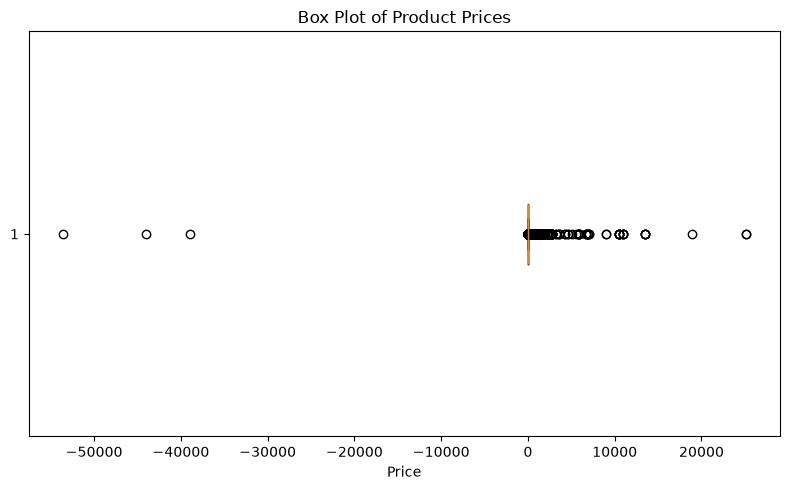

In [17]:
# Select the regression target
target = df["Price"].dropna()

# Calculate the first and third quartiles
Q1 = target.quantile(0.25)
Q3 = target.quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Define outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = target[
    (target < lower_bound) |
    (target > upper_bound)
]

# Display the results
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Potential Outlier Count:", len(outliers))

# Visualize the target variable
plt.figure(figsize=(8, 5))
plt.boxplot(target, vert=False)
plt.title("Box Plot of Product Prices")
plt.xlabel("Price")
plt.tight_layout()
plt.show()

## Step 3: Code Explanation and Analysis

**1. `.quantile(0.25)`**

Calculates the first quartile (Q1), below which approximately 25% of the values fall.

**2. `.quantile(0.75)`**

Calculates the third quartile (Q3), below which approximately 75% of the values fall.

**3. `IQR = Q3 - Q1`**

Calculates the interquartile range, which measures the spread of the middle 50% of the data.

**4. Outlier boundaries**

The lower and upper boundaries are calculated using 1.5 times the IQR. Values outside these boundaries are flagged as potential outliers under the IQR rule.

**5. Outlier filtering**

The code identifies and counts values outside the boundaries. It does not remove them from the original dataset.

**6. `plt.boxplot()`**

Creates a box plot that helps visualize the central spread of prices and potential outliers.

### How to Interpret the Output

- Values below the lower boundary or above the upper boundary are flagged as potential outliers.
- Points beyond the whiskers in a box plot may indicate potential outliers.
- Some flagged values may be genuine business observations rather than errors.

### Where It Is Used in AI/ML

Outlier analysis helps us investigate unusual target values before training regression models. Depending on the business objective, we may retain, correct, transform, or exclude certain values after investigation.

**Important:** This analysis uses `Price` as an example regression target. No records are automatically deleted or modified.

## Step 1: Understand the Concept – Importance of Target Analysis Before ML

Target analysis is an important step before training a machine learning model. It helps us understand the target variable that the model is expected to predict.

For classification problems, target analysis helps identify class counts, class percentages, and class imbalance.

For regression problems, it helps us understand the target distribution, mean, median, variance, standard deviation, skewness, and potential outliers.

**Why It Is Important:**
- Helps identify missing or unusual target values.
- Helps us understand the distribution of the target variable.
- Helps identify class imbalance in classification tasks.
- Helps us select suitable evaluation metrics and modelling approaches.
- Helps prevent misleading conclusions during model development.

**Important:** The target variable must be selected according to the real business objective. A column should not be treated as a target just because it contains numerical values.

## Step 2: Demonstrate the Concept – Real-World Example

Imagine an online retail business that wants to predict product prices using a regression model.

Before training the model, the data analyst examines the `Price` column.

| Analysis | Purpose |
|---|---|
| Target Distribution | Understand how prices are spread |
| Mean and Median | Understand the average and central price |
| Variance and Standard Deviation | Measure price variability |
| Skewness | Understand the shape of the price distribution |
| Outliers | Identify unusual prices for investigation |

This analysis helps the analyst understand the target variable before building the model.

**AI/ML Application:** Target analysis supports better data preparation and helps the analyst choose appropriate modelling and evaluation methods.

**Note:** `Price` is only an example target here. The correct target depends on the actual business objective.

Target Analysis: Price
-----------------------------------
Number of Records: 525461
Mean: 4.69
Median: 2.1
Variance: 21353.075
Standard Deviation: 146.1269
Skewness: -140.7684
Potential Outlier Count: 35273


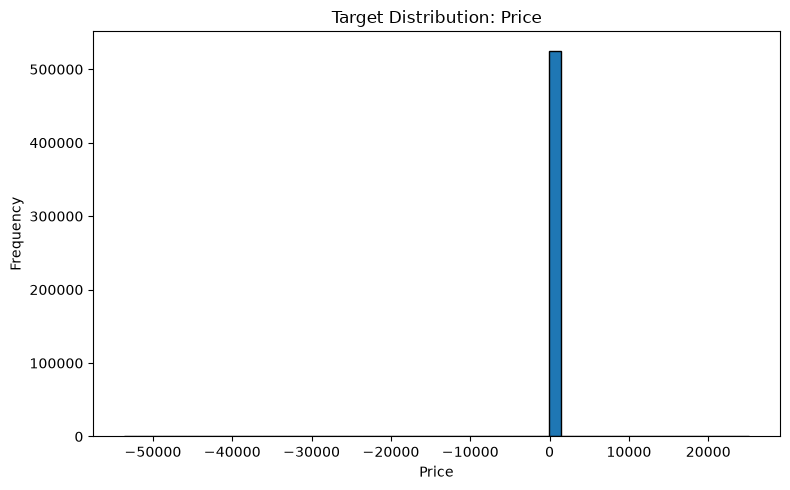

In [20]:
# Select the target variable
target = df["Price"].dropna()

# Display basic target statistics
print("Target Analysis: Price")
print("-" * 35)

print("Number of Records:", target.count())
print("Mean:", round(target.mean(), 2))
print("Median:", round(target.median(), 2))
print("Variance:", round(target.var(), 4))
print("Standard Deviation:", round(target.std(), 4))
print("Skewness:", round(target.skew(), 4))

# Identify potential outliers using the IQR method
Q1 = target.quantile(0.25)
Q3 = target.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = target[
    (target < lower_bound) | (target > upper_bound)
]

print("Potential Outlier Count:", len(outliers))

# Visualize the target distribution
plt.figure(figsize=(8, 5))
plt.hist(target, bins=50, edgecolor="black")
plt.title("Target Distribution: Price")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Step 3: Code Explanation and Analysis

**1. `df["Price"].dropna()`**

Selects the `Price` column and excludes missing values from the analysis without modifying the original dataset.

**2. `target.count()`**

Counts the number of non-missing target values.

**3. `target.mean()` and `target.median()`**

Calculate the mean and median to understand the average and central price values.

**4. `target.var()` and `target.std()`**

Calculate variance and standard deviation to understand how widely prices vary.

**5. `target.skew()`**

Measures the asymmetry of the price distribution.

**6. IQR Method**

Calculates the first quartile, third quartile, and interquartile range to identify potential outliers outside the specified boundaries.

**7. `plt.hist()`**

Displays a histogram to help us understand the distribution of product prices.

### How to Interpret the Output

- Mean and median describe the central values of the target.
- Variance and standard deviation describe its spread.
- Skewness describes the distribution's asymmetry.
- Potential outlier counts indicate how many values fall outside the IQR boundaries.
- The histogram helps us visualize where prices are concentrated.

### Where It Is Used in AI/ML

Target analysis helps data analysts understand the target variable, identify possible data-quality issues, and make informed decisions before training a regression model.

**Important:** The code only analyzes the `Price` column. It does not remove outliers or change the original dataset. The appropriate target variable must always match the real business objective.